# Projet Kaggle : Binary Prediction of Poisonous Mushrooms
LAIB Hannah & WELLECAN Mathéo 

In [9]:
import math
import csv

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Imputation (l'import experimental doit venir avant IterativeImputer)
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer

# Recherche d'hyperparamètres expérimentale (doit venir avant HalvingRandomSearchCV)
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    HalvingRandomSearchCV,
)

# Modèles
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
    GradientBoostingClassifier,
)
from sklearn.svm import LinearSVC, SVC
from sklearn.neighbors import KNeighborsClassifier

# Prétraitement
from sklearn.preprocessing import (
    OrdinalEncoder,
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer,
)
from sklearn.compose import (
    ColumnTransformer,
    make_column_transformer,
    make_column_selector, 
)
from sklearn.pipeline import make_pipeline

# Distributions pour la recherche aléatoire
from scipy.stats import loguniform, randint, uniform

# Métrique
from sklearn.metrics import make_scorer, matthews_corrcoef

## documment utiliser : 
doc seaborn : https://seaborn.pydata.org/index.html  
Kaggle: https://www.kaggle.com/competitions/playground-series-s4e8/data?select=test.csv  
Doc scikit: https://scikit-learn.org/stable/   
Doc pandas: https://pandas.pydata.org/docs/  
Lien sur les arbres : https://scikit-learn.org/stable/modules/tree.html#tree  
Lien sur les ensembles : https://scikit-learn.org/stable/modules/ensemble.html#ensemble  
Parameter Tuning: https://scikit-learn.org/stable/modules/grid_search.html  
HistGradBoosting: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html#sklearn.ensemble.HistGradientBoostingClassifier  
RandomForest: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html#sklearn.ensemble.RandomForestClassifier    


# I. Visualisation des donnée 

In [10]:
train = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/train.csv', index_col='id')
test = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/test.csv', index_col='id')
train.info()
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 3116945 entries, 0 to 3116944
Data columns (total 21 columns):
 #   Column                Dtype  
---  ------                -----  
 0   class                 str    
 1   cap-diameter          float64
 2   cap-shape             str    
 3   cap-surface           str    
 4   cap-color             str    
 5   does-bruise-or-bleed  str    
 6   gill-attachment       str    
 7   gill-spacing          str    
 8   gill-color            str    
 9   stem-height           float64
 10  stem-width            float64
 11  stem-root             str    
 12  stem-surface          str    
 13  stem-color            str    
 14  veil-type             str    
 15  veil-color            str    
 16  has-ring              str    
 17  ring-type             str    
 18  spore-print-color     str    
 19  habitat               str    
 20  season                str    
dtypes: float64(3), str(18)
memory usage: 499.4 MB
<class 'pandas.DataFrame'>
RangeIndex: 207

## I.1 Visualisation de la distribution 
### I.1.1 Les données quantitatives
Dans cette partie, seules les variables `cap-diameter`, `stem-height` et `stem-width` seront traitées, car ce sont les seules variables quantitatives du jeu de données. Nous utilisons la fonction `displot` de Seaborn pour visualiser la répartition de leurs valeurs.

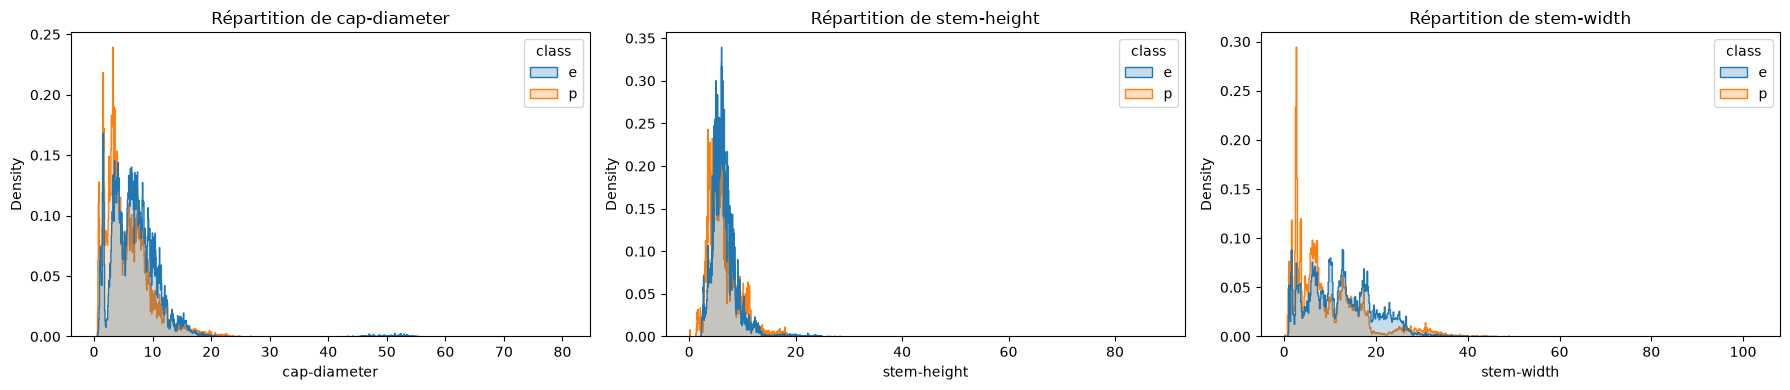

,min,max,mean,median,std,etendue,IQR,cv
cap-diameter,0.03,80.67,6.31,5.75,4.66,80.64,4.92,0.74
stem-height,0.00,88.72,6.35,5.88,2.70,88.72,2.74,0.43
stem-width,0.00,102.90,11.15,9.65,8.10,102.90,10.66,0.73


In [11]:
quantitatives = train.select_dtypes(include="number").columns.tolist()
qualitativestatives = train.select_dtypes(exclude="number").columns.tolist()
fig, axes = plt.subplots(1, len(quantitatives), figsize=(18, 4))

for ax, col in zip(axes, quantitatives):
    sns.histplot(data=train, x=col, hue="class",
                 stat="density", common_norm=False,
                 element="step", ax=ax)
    ax.set_title(f"Répartition de {col}")

plt.tight_layout()
plt.show()
resume = train[quantitatives].agg(["min", "max", "mean", "median", "std"]).T
resume["etendue"] = resume["max"] - resume["min"]
resume["IQR"] = (train[quantitatives].quantile(0.75)
                 - train[quantitatives].quantile(0.25))
resume["cv"] = resume["std"] / resume["mean"]
resume.round(2)

Pour régulariser les distributions, nous appliquons le logarithme.

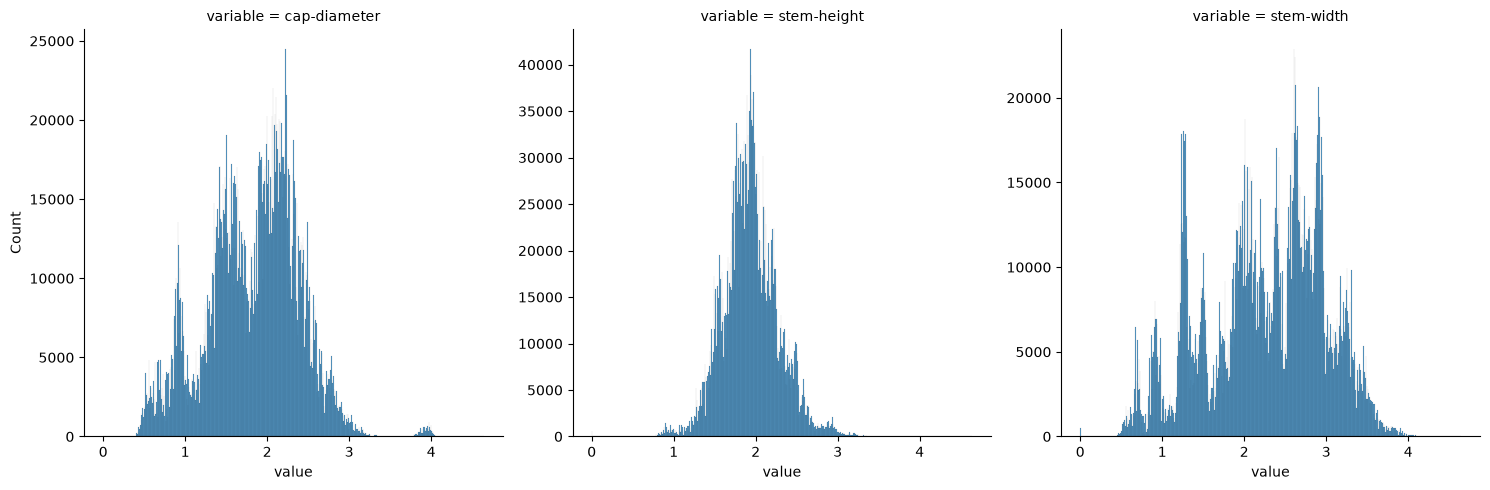

In [12]:
df2=train[quantitatives].melt()
df2["value"]=np.log1p(df2["value"])
sns.displot(df2,x="value",col="variable",facet_kws={"sharex": False, "sharey": False})

Les trois variables quantitatives présentent une distribution asymétrique à droite (moyenne supérieure à la médiane). Les étendues sont très larges (jusqu’à 103 pour `stem-width`) par rapport à la dispersion centrale (IQR de 2,7 à 10,7), ce qui révèle des valeurs extrêmes qui seront examinées et éventuellement plafonnées avant la modélisation. Un traitement de ces variables (plafonnement des valeurs extrêmes, transformation logarithmique) pourra être appliqué selon le modèle retenu : les modèles à base d’arbres y sont peu sensibles, contrairement aux modèles linéaires.

### I.1.1 Les données quantitatif 

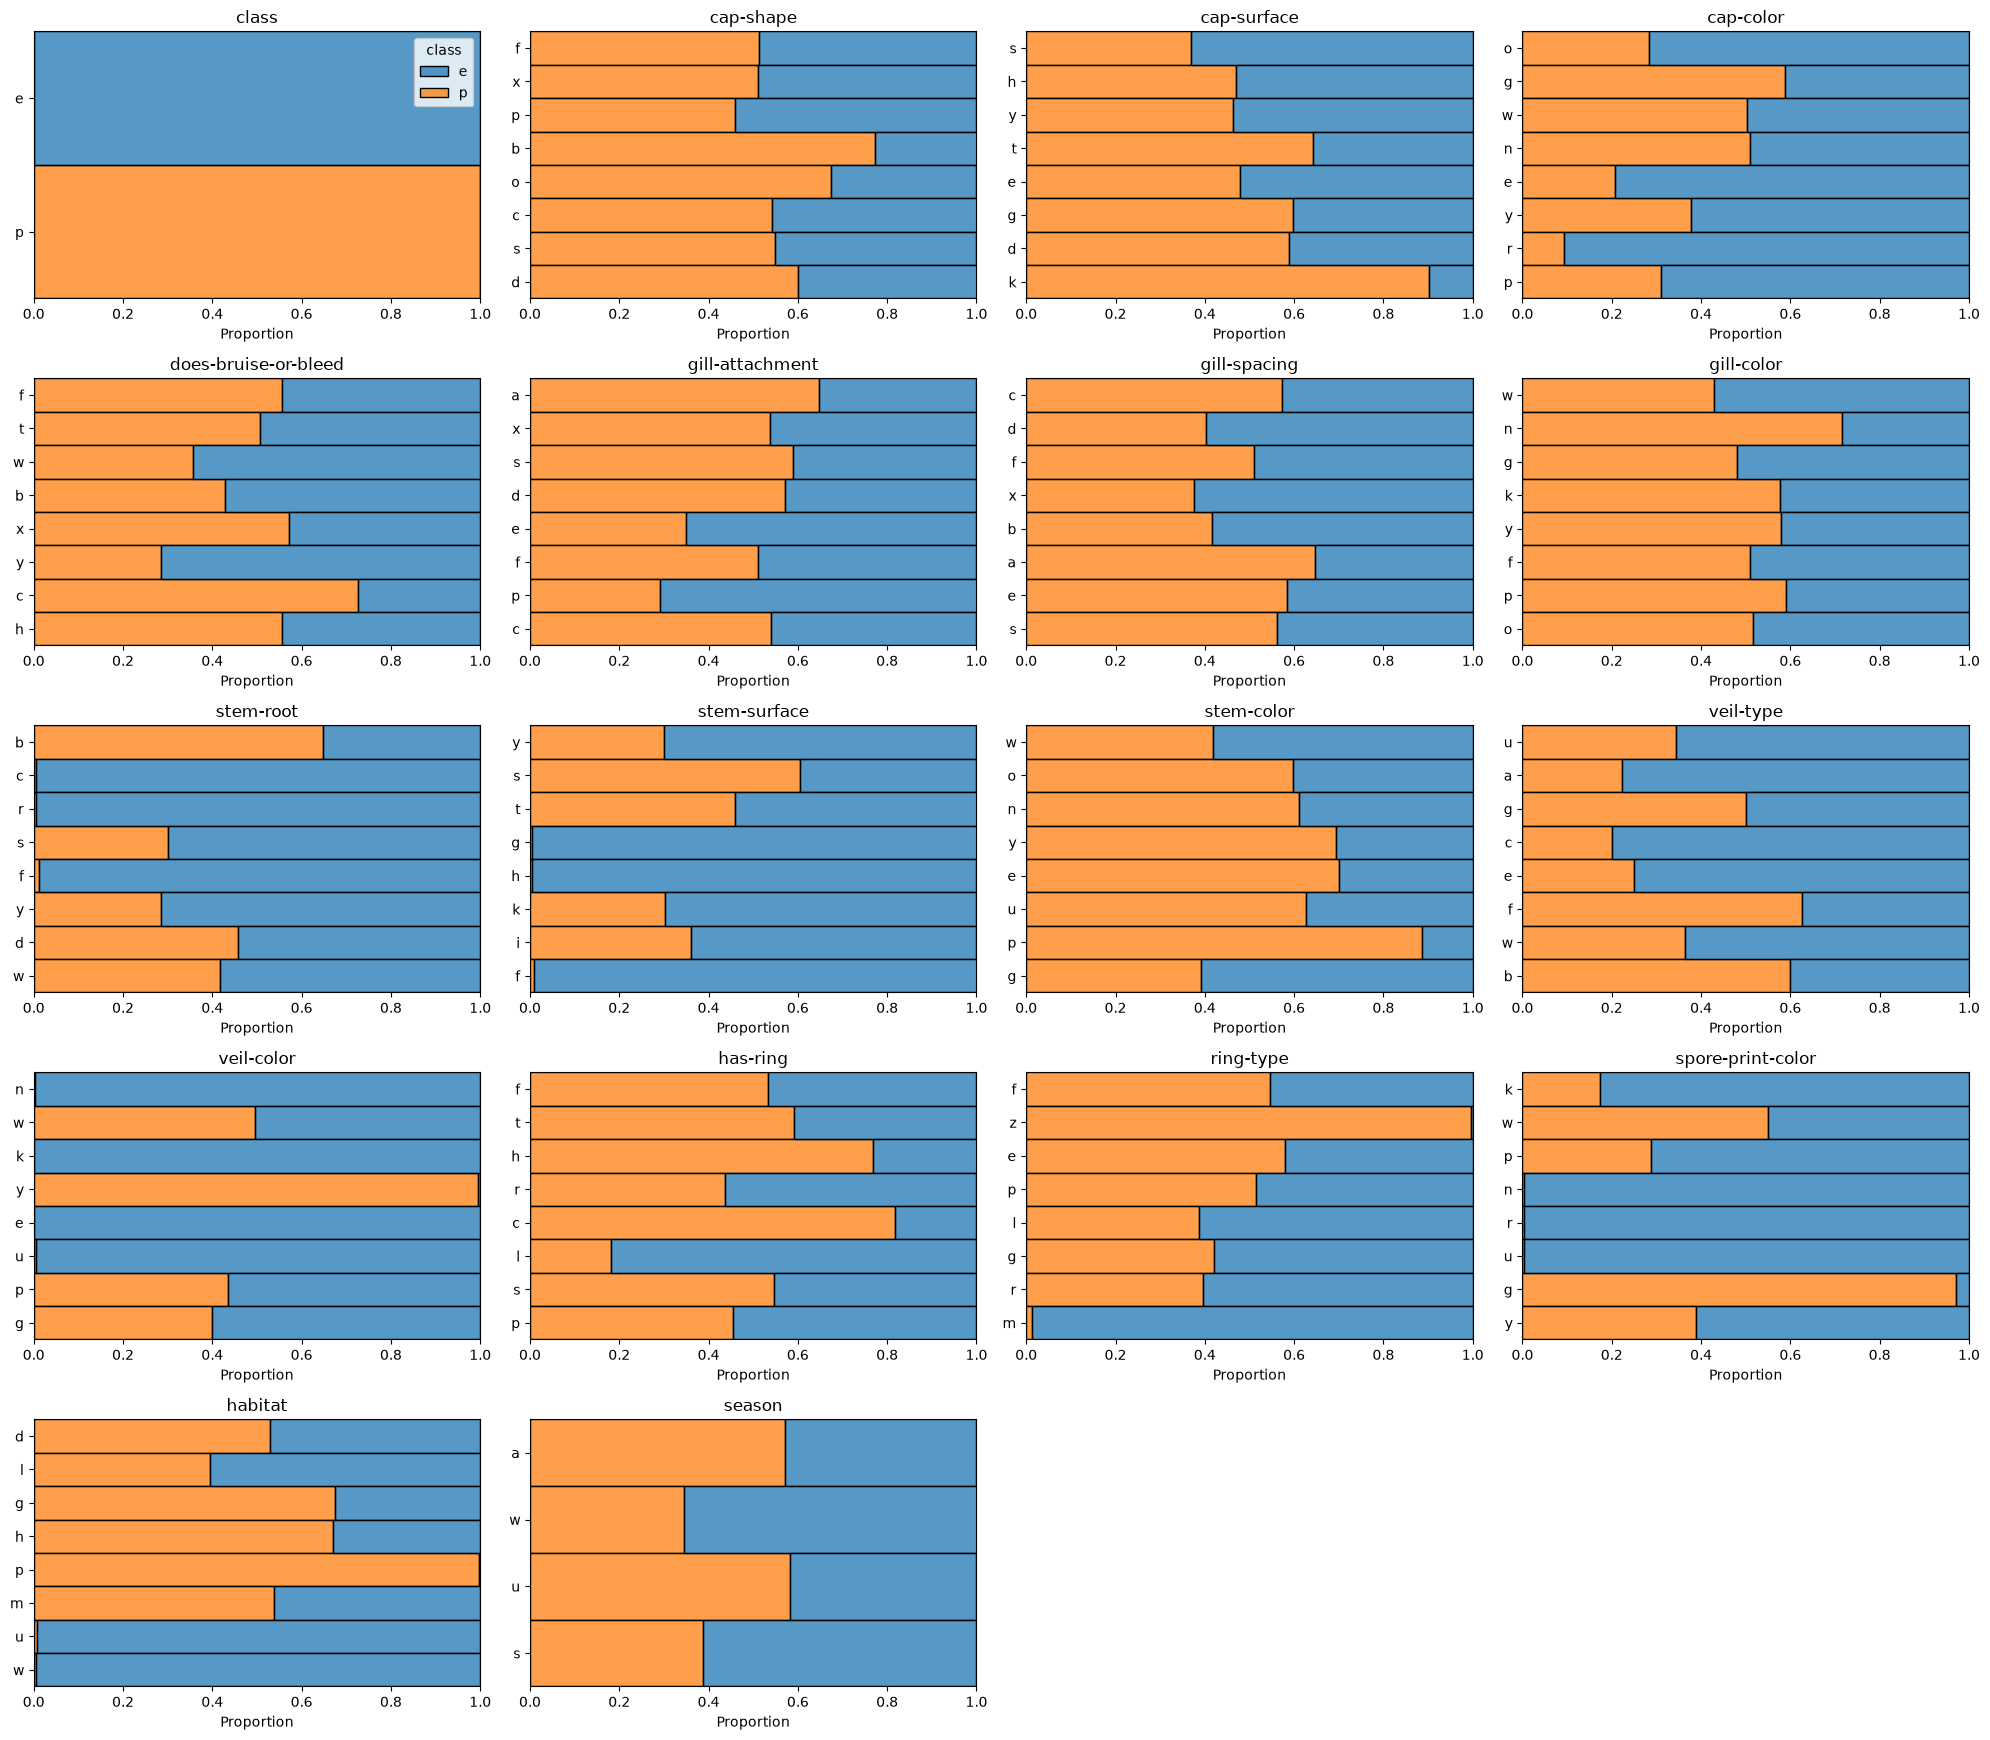

,nb_modalites,modalite_dominante,part_dominante_%,nb_modalites_rares(<1%),manquants_%
veil-type,22,u,99.95,21,94.88
spore-print-color,32,k,40.15,25,91.43
stem-root,38,b,46.07,34,88.45
veil-color,24,w,74.22,18,87.94
stem-surface,60,s,28.84,53,63.55
gill-spacing,48,c,71.62,45,40.37
cap-surface,83,t,18.84,72,21.53
gill-attachment,78,a,24.91,71,16.81
ring-type,40,f,82.90,33,4.13
class,2,p,54.71,0,0.00


In [13]:
ncols = 4
nrows = math.ceil(len(qualitativestatives) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows))
axes = axes.ravel()

for ax, col in zip(axes, qualitativestatives):
    top = train[col].value_counts().nlargest(8).index
    sub = train[train[col].isin(top)]
    sns.histplot(data=sub, y=col, hue="class", multiple="fill",
                 stat="proportion", ax=ax, legend=(ax is axes[0]))
    ax.set_title(col)
    ax.set_ylabel("")

for ax in axes[len(qualitativestatives):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()
resume_cat = pd.DataFrame({
    "nb_modalites": train[qualitativestatives].nunique(),
    "modalite_dominante": train[qualitativestatives].mode().iloc[0],
    "part_dominante_%": [train[c].value_counts(normalize=True).iloc[0] * 100
                         for c in qualitativestatives],
    "nb_modalites_rares(<1%)": [(train[c].value_counts(normalize=True) < 0.01).sum()
                                for c in qualitativestatives],
    "manquants_%": train[qualitativestatives].isna().mean() * 100,
})
resume_cat.round(2).sort_values("manquants_%", ascending=False)

Quatre variables qualitativestatives (`veil-type`, `spore-print-color`, `stem-root`, `veil-color`) sont écartées dans un premier temps, car elles sont presque entièrement manquantes (88 % à 95 %), `veil-type` étant en outre quasi constante. Les modalités rares y seront regroupées et les valeurs manquantes traitées explicitement. Cette sélection sera confirmée en comparant les performances du modèle avec et sans les variables écartées.

## I.2 Visualisation de la correspondance des different jeux de tests

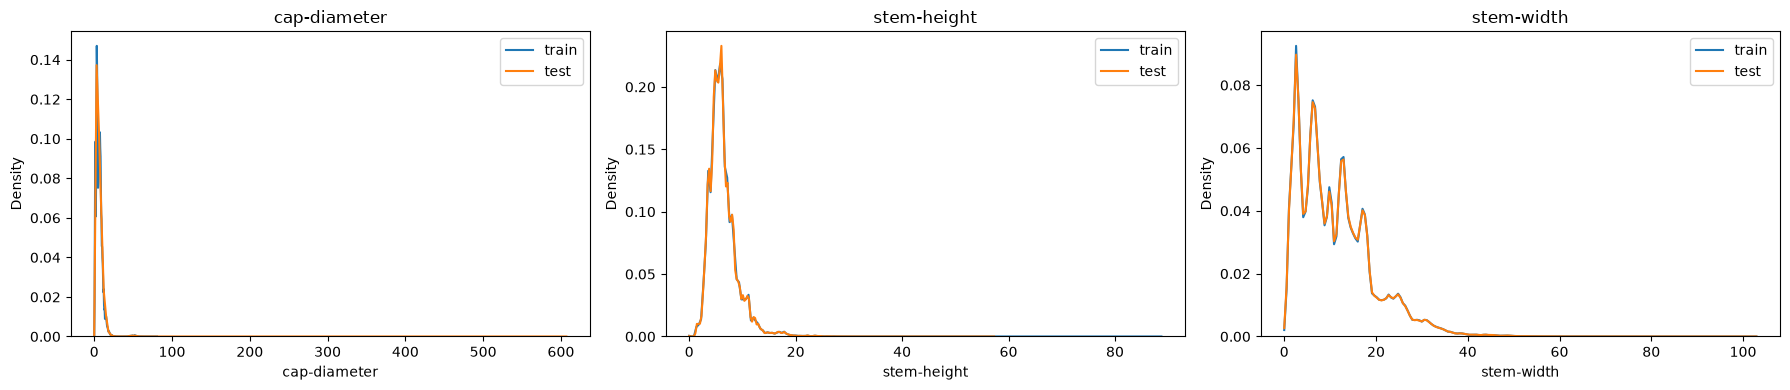

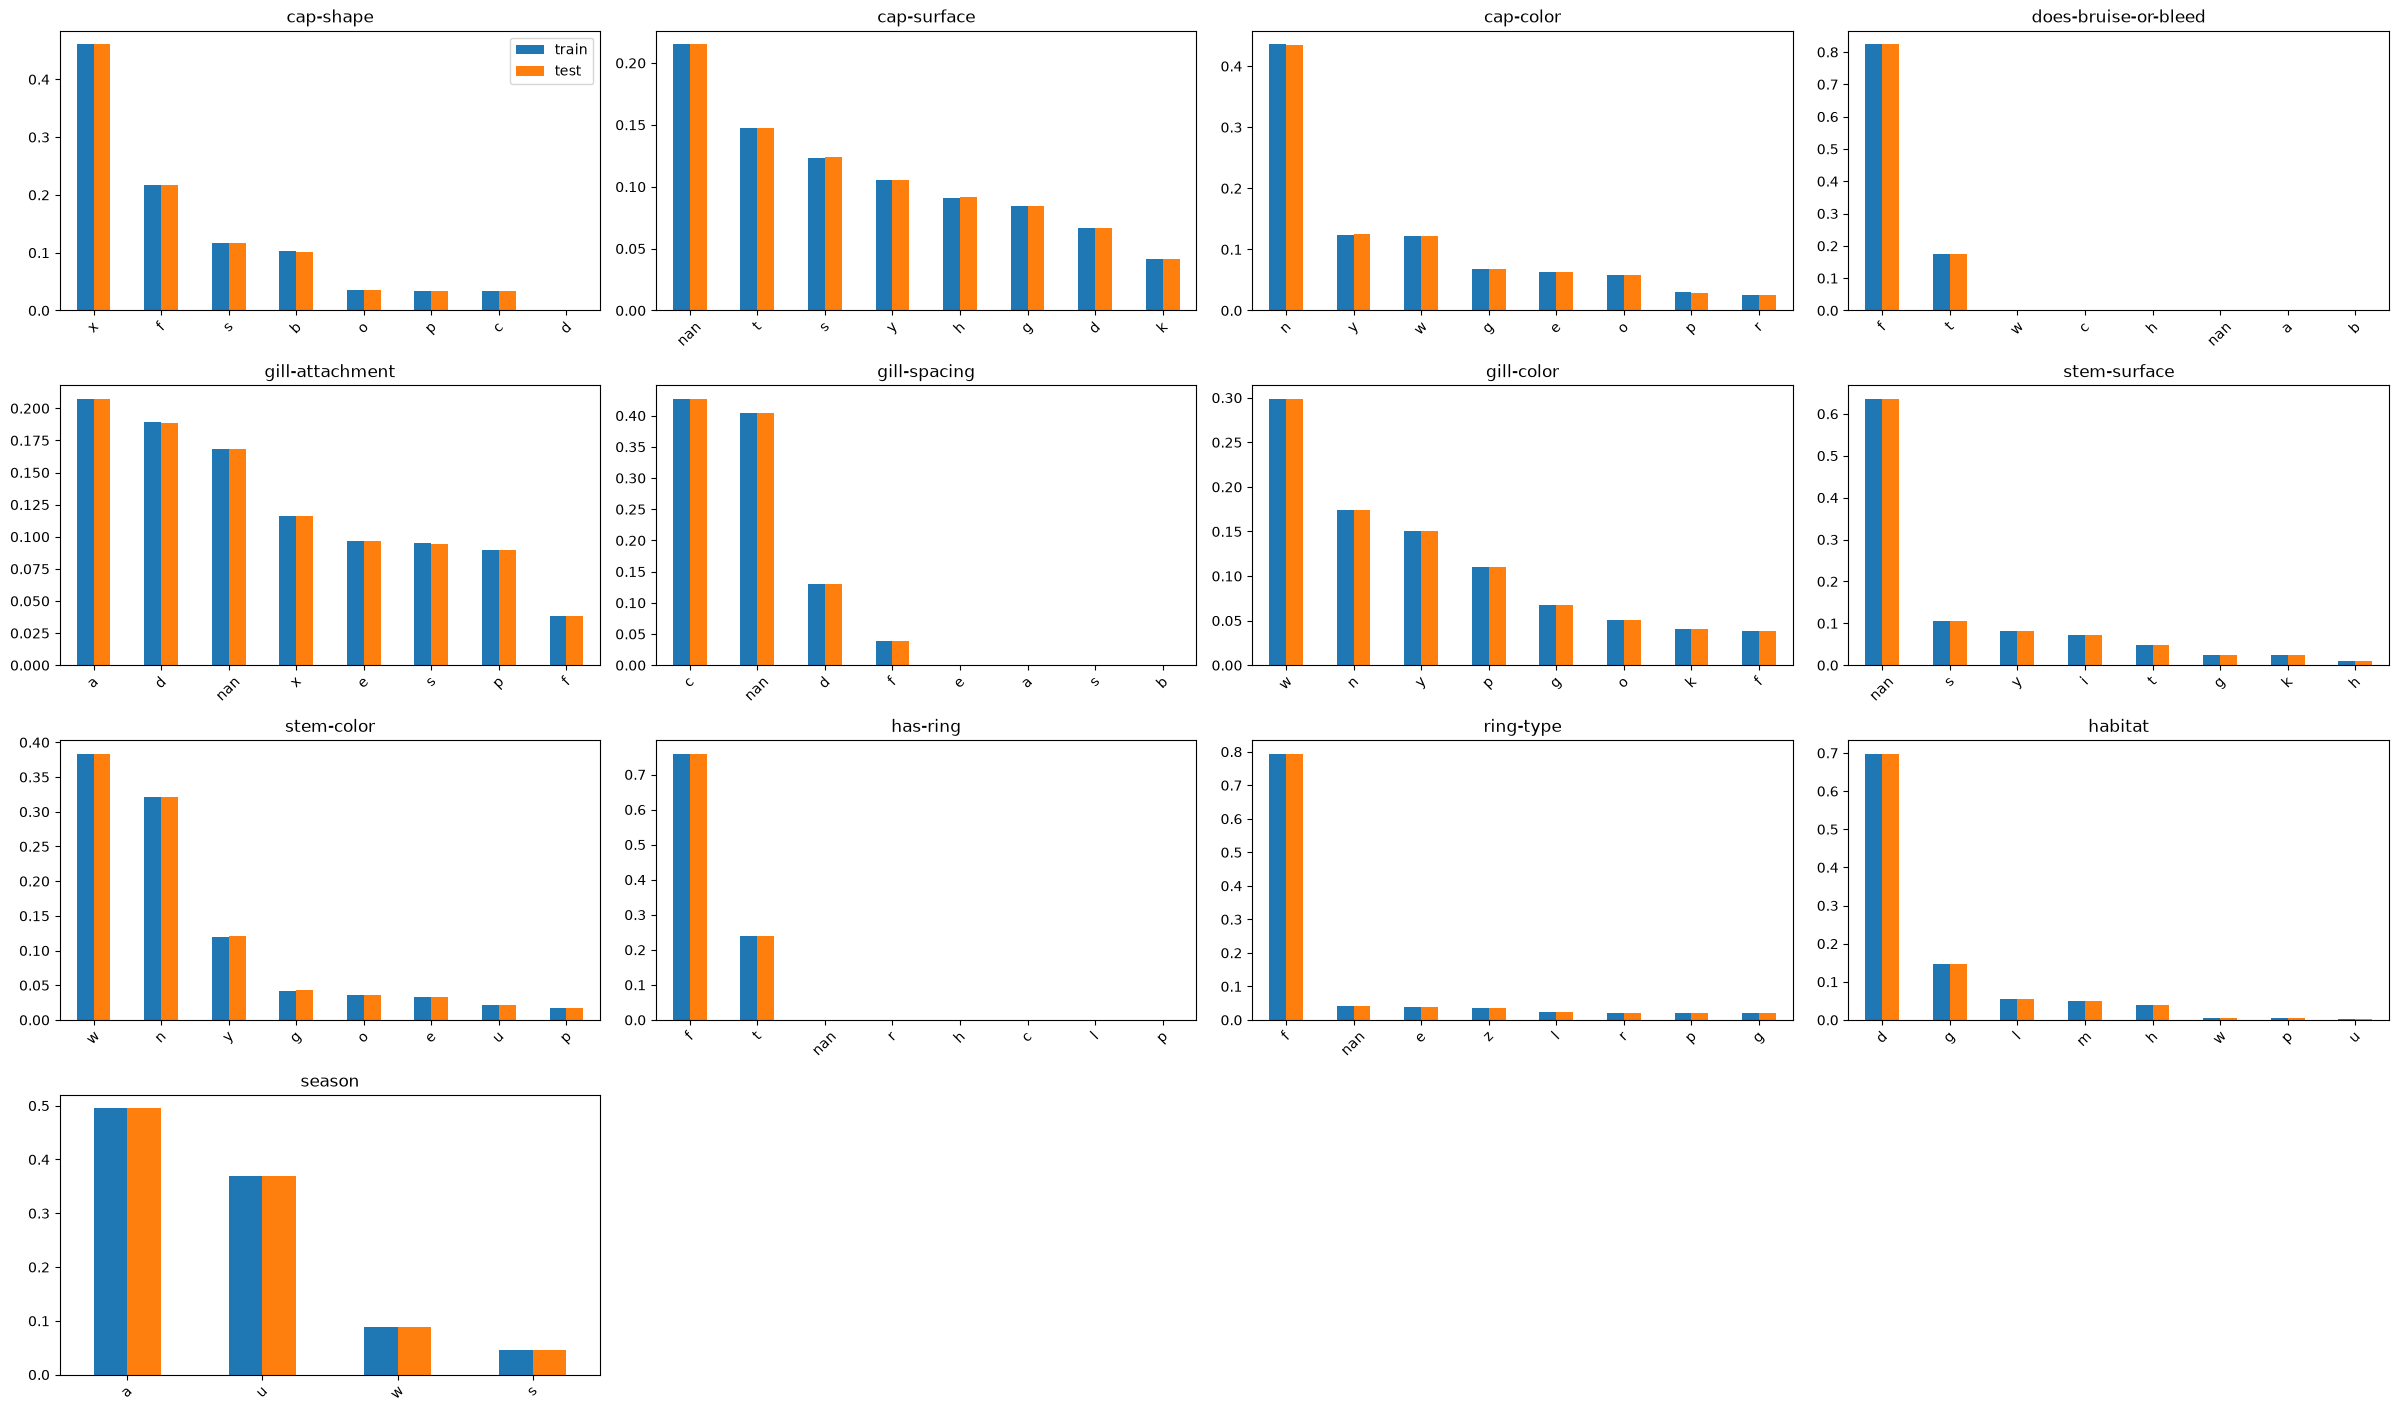

In [15]:
test = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/test.csv', index_col='id')
qualitatives = test.select_dtypes(exclude="number").columns.tolist()

fig, axes = plt.subplots(1, len(quantitatives), figsize=(18, 4))
for ax, col in zip(axes, quantitatives):
    sns.kdeplot(data=train, x=col, label="train", cut=0, common_norm=False, ax=ax)
    sns.kdeplot(data=test,  x=col, label="test",  cut=0, common_norm=False, ax=ax)
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

ncols = 4
nrows = math.ceil(len(qualitatives) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.5 * nrows))
axes = axes.ravel()
a_ecarter = ["veil-type", "spore-print-color", "stem-root", "veil-color"]

qualitatives = [c for c in train.select_dtypes(exclude="number").columns
                if c in test.columns and c not in a_ecarter]
for ax, col in zip(axes, qualitatives):
    comp = pd.DataFrame({
        "train": train[col].value_counts(normalize=True, dropna=False),
        "test":  test[col].value_counts(normalize=True, dropna=False),
    }).fillna(0)
    comp.nlargest(8, "train").plot(kind="bar", ax=ax, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)

for ax in axes[len(qualitatives):]:
    ax.set_visible(False)

axes[0].legend(["train", "test"])
plt.tight_layout()
plt.show()

Grâce aux différents graphiques générés, on remarque que le jeu d'entraînement (train) présente une bonne correspondance avec le jeu de test (test). Cette cohérence confirme que nos données sont saines et prêtes pour la suite du projet.

## II. Traitement des données et Recherche de modèle 
Nous avons abordé cette partie de deux façons différentes : une approche plutôt **expérimentale** et une approche plutôt **documentaire**. Nous avons jugé pertinent de présenter les deux, car elles permettent d'aborder le problème avec des principes différents. Dans les deux approches, nous effectuons une phase de test sur un petit jeu de données, car un entraînement sur l'ensemble des données demanderait trop de ressources côté machine.
### II.1 Version Expérimentale

In [16]:
def valeur_manquante(train, a_ecarter, mods, test=None):
    train = train.drop(columns=[c for c in a_ecarter if c in train.columns]).copy()
    if test is not None:
        test = test.drop(columns=[c for c in a_ecarter if c in test.columns]).copy()

    num_cols = train.select_dtypes(include="number").columns.tolist()
    cat_cols = train.select_dtypes(exclude="number").columns.drop("class", errors="ignore").tolist()

    if mods == "SI":      # passer au log 
        imp_num = SimpleImputer(strategy="median")
        imp_cat = SimpleImputer(strategy="constant", fill_value="manquant")

    elif mods == "M":     # médiane (num) + mode (cat)
        imp_num = SimpleImputer(strategy="median")
        imp_cat = SimpleImputer(strategy="most_frequent")

    elif mods == "KNN":   # KNN (num) + mode (cat) : lent, à tester sur échantillon
        imp_num = KNNImputer(n_neighbors=20)
        imp_cat = SimpleImputer(strategy="most_frequent")

    elif mods == "IMP":   # itératif (num) + mode (cat) : lent
        imp_num = IterativeImputer(estimator=HistGradientBoostingRegressor(),
                                   max_iter=5, random_state=0)
        imp_cat = SimpleImputer(strategy="most_frequent")

    else:                 # aucune imputation
        return (train, test) if test is not None else train

    # ajustement sur le TRAIN uniquement
    train[num_cols] = imp_num.fit_transform(train[num_cols])
    train[cat_cols] = imp_cat.fit_transform(train[cat_cols])

    if test is not None:
        test[num_cols] = imp_num.transform(test[num_cols])
        test[cat_cols] = imp_cat.transform(test[cat_cols])
        return train, test
    return train

def entrainement_des_modele(train, test, mods="R", type_mod="HistGradientBoostingClassifier"):
    a_ecarter = ["veil-type", "spore-print-color", "stem-root", "veil-color"]
    entrai, test = valeur_manquante(train, a_ecarter, mods, test)
    # titre de la partie
    y = entrai["class"]
    X = entrai.drop(columns=["class"]).copy()
    cat_cols = X.select_dtypes(include=["object", "str"]).columns    
    for col in cat_cols:  # transformer un v
        X[col] = X[col].astype("category")

    X_train, X_val, y_train, y_val = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # encodeur pour les modèles qui n'acceptent pas le texte / les catégories
    encodeur = ColumnTransformer(
        [("cat", OrdinalEncoder(handle_unknown="use_encoded_value",
                                unknown_value=-1,
                                encoded_missing_value=-1), list(cat_cols))],
        remainder="passthrough"
    )

    if type_mod == "HistGradientBoostingClassifier":
        model = HistGradientBoostingClassifier(
            categorical_features="from_dtype",
            max_iter=100,
            learning_rate=0.1,
            random_state=42
        )
    elif type_mod == "IterativeImputer":
        # IterativeImputer n'a pas de predict : on l'insère dans un pipeline
        # (encodage -> imputation -> classifieur) pour qu'il soit utilisable
        model = make_pipeline(
            encodeur,
            IterativeImputer(
                estimator=RandomForestRegressor(n_estimators=25, max_depth=12, n_jobs=-1, random_state=0),
                max_iter=5,
                initial_strategy= 'most_frequent',
                random_state=0,
            ),
            HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, random_state=42)
        )
    elif type_mod == "RandomForestClassifier":
        model = make_pipeline(
            encodeur,
            RandomForestClassifier(
    n_estimators=50, max_depth=400, max_features=None,
    max_samples=0.557, min_samples_leaf=8, min_samples_split=9,
    min_impurity_decrease=0.0007, n_jobs=-1, random_state=42,
))
    elif type_mod == "GradientBoostingClassifier":
        model = make_pipeline(
            encodeur,
            GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42)
        )
    else:
        print("le modele que vous souhaiter tester n'existe pas, le modele par defaut est HistGradientBoostingClassifier")
        model = HistGradientBoostingClassifier(
            categorical_features="from_dtype",
            max_iter=100,
            learning_rate=0.1,
            random_state=42
        )

    model.fit(X_train, y_train)
    #X_test = val_manquant(test, seuil, ops)
    X_test = test[X.columns]
    for col in cat_cols:
        X_test[col] = X_test[col].where(X_test[col].isin(X[col].cat.categories))
        X_test[col] = pd.Categorical(X_test[col], categories=X[col].cat.categories)

    predictions = model.predict(X_test)
    y_pred = model.predict(X_val)
    mcc = matthews_corrcoef(y_val, y_pred)
    print(f"MCC sur validation : {mcc:.4f}")

    return model, predictions, mcc

def copi_fichier(n, train,test):
    train_copie = []
    test_copie = []
    for i in range(n):
        train_copie.append(train.copy())
        test_copie.append(test.copy())
    return train_copie, test_copie 

In [17]:
imputations = ["SI", "M", "KNN", "IMP"]
types_mod = ["HistGradientBoostingClassifier", "IterativeImputer",
             "RandomForestClassifier", "GradientBoostingClassifier"]

train = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/train.csv', index_col='id')
test = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/test.csv', index_col='id')

train_s = train.head(50000)
test_s = test.head(50000)

taille = len(imputations) * len(types_mod)   # 16
i = 1
resul = []

for val_manq in imputations:
    for type_mo in types_mod:
        print(f"[{i}/{taille}] mehtode d'imputation valeur manquante ={val_manq}, type de modele={type_mo}")
        mod, preds, mcc = entrainement_des_modele(train_s, test_s,mods =val_manq, type_mod=type_mo)
        resul.append((val_manq, type_mo, mcc))
        i += 1

df_resul = pd.DataFrame(resul, columns=["imputation valeur manquante", "type de modele utiliser", "mcc"])
df_resul = df_resul.sort_values("mcc", ascending=False).reset_index(drop=True)
print(df_resul)

meilleur = df_resul.iloc[0]
print(f"\nMeilleur MCC : {meilleur['mcc']:.4f} "
      f"({meilleur['imputation valeur manquante']}, ops={meilleur['type de modele utiliser']})")

[1/16] mehtode d'imputation valeur manquante =SI, type de modele=HistGradientBoostingClassifier
MCC sur validation : 0.9784
[2/16] mehtode d'imputation valeur manquante =SI, type de modele=IterativeImputer
MCC sur validation : 0.9720
[3/16] mehtode d'imputation valeur manquante =SI, type de modele=RandomForestClassifier
MCC sur validation : 0.9275
[4/16] mehtode d'imputation valeur manquante =SI, type de modele=GradientBoostingClassifier
MCC sur validation : 0.8136
[5/16] mehtode d'imputation valeur manquante =M, type de modele=HistGradientBoostingClassifier
MCC sur validation : 0.9742
[6/16] mehtode d'imputation valeur manquante =M, type de modele=IterativeImputer
MCC sur validation : 0.9701
[7/16] mehtode d'imputation valeur manquante =M, type de modele=RandomForestClassifier
MCC sur validation : 0.9398
[8/16] mehtode d'imputation valeur manquante =M, type de modele=GradientBoostingClassifier
MCC sur validation : 0.8449
[9/16] mehtode d'imputation valeur manquante =KNN, type de model

In [19]:
train = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/train.csv', index_col='id')
test = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/test.csv', index_col='id')

train_s = train
test_s = test
mod, preds, mcc = entrainement_des_modele(train_s, test_s,mods ="SI", type_mod="RandomForestClassifier")
print(mcc)
print(preds)

MCC sur validation : 0.9133
0.9133214612049178
['e' 'p' 'p' ... 'p' 'e' 'e']


### II.2 Version documentaire
#### Régression Logistique
On teste LogisticRegression et LogisticRegressionCV qui en plus de LogisticRegression teste plusieurs valeurs d'un paramètre du modèle pour choisir le meilleur.  

Pour ce modèle on va traité de la façon suivante : 
1. Colonnes numériques
   1. SimpleImputer("median")
   2. Passer au log
   3. StandardScaler()
2. Colonne catégorielles
   1. SimpleImputer("constant")
   2. OneHotEncoder(seuil pour une colonne infrequent)
#### Arbre de décision et Forêts aléatoires
On va traité les données différemment pour les arbres et les forêts :
1. Colonnes numériques
   1. SimpleImputer("median")
2. Colonnes catégorielles
   1. SimpleImputer("constant")
   2. OrdinalEncoder(sans seuil)
#### Modèles Flowchart
Pour LinearSVC et SVC on utilise le même prétraitement que LogisticRegression.  
Pour KNeighborsClassifier on utilise aussi le même prétraitement que LogisticRegression mais avec un palier à 5% pour les variables rares.  
Pour GradientBoostingClassifier on utilise celui des arbres.  
Pour HistGradientBoostingClassifier on ne traite pas les données numériques et pour les qualitativestatives on fait un ordinal encoder 

In [20]:
test = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/test.csv', index_col='id')
train = pd.read_csv('/home/hannah/projet_python/playground-series-s4e8/train.csv', index_col='id')
quanti=list(train.select_dtypes(include=["float64"]).columns)
CT_LR_qualitatives=list(train.select_dtypes(include=["str"]).drop(columns="class").columns)
train_y=train["class"]
train_x=train.drop(columns="class")
#on fait des test sur un sous-ensemble du dataframe
df_train, _ = train_test_split(train,train_size=0.05,stratify=train["class"])
#on sépare la colonne cible
df_train_x=df_train.drop(columns="class")
df_train_y=df_train["class"]

# Regression Logistique 
CT_LR_quanti=make_pipeline(SimpleImputer(strategy="median"),FunctionTransformer(np.log1p),StandardScaler())
CT_LR_qualitatives=make_pipeline(SimpleImputer(strategy="constant",fill_value="Manquant"),OneHotEncoder(min_frequency=0.01,handle_unknown="infrequent_if_exist"))

CT_LR=make_column_transformer([CT_LR_qualitatives,qualitatives],[CT_LR_quanti,quanti],verbose_feature_names_out=False)

Pipe_LR=make_pipeline(CT_LR,LogisticRegression(max_iter=1000))
Pipe_LRCV=make_pipeline(CT_LR,LogisticRegressionCV(max_iter=1000))

# Arbre et foret :
CT_tree_qualitatives=make_pipeline(SimpleImputer(strategy="constant",fill_value="Manquant"),OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1))

CT_tree=make_column_transformer([CT_tree_qualitatives,qualitatives],[SimpleImputer(strategy="median"),quanti],verbose_feature_names_out=False)

Pipe_tree=make_pipeline(CT_tree,DecisionTreeClassifier())
Pipe_forest=make_pipeline(CT_tree,RandomForestClassifier())

# Flowchart
CT_KN_qualitatives=CT_LR_qualitatives=make_pipeline(SimpleImputer(strategy="constant",fill_value="Manquant"),OneHotEncoder(min_frequency=0.05,handle_unknown="infrequent_if_exist"))

CT_hist = make_column_transformer( (OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
     make_column_selector(dtype_exclude="number")),
    remainder="passthrough",
)


CT_KN=make_column_transformer([CT_KN_qualitatives,qualitatives],[SimpleImputer(strategy="median"),quanti],verbose_feature_names_out=False)

Pipe_LSVC=make_pipeline(CT_LR,LinearSVC())
Pipe_SVC=make_pipeline(CT_LR,SVC())
Pipe_GB=make_pipeline(CT_tree,GradientBoostingClassifier())
Pipe_HGB=make_pipeline(CT_hist,HistGradientBoostingClassifier())
Pipe_KN=make_pipeline(CT_KN,KNeighborsClassifier())

In [21]:
model_classique={"Régression Logistique":Pipe_LR,"Régression Logistique CV":Pipe_LRCV,"Arbre de décision":Pipe_tree,"Forêt aléatoire":Pipe_forest}

for i in model_classique:
    model_classique[i].fit(df_train_x,df_train_y)

tab_score_classique=pd.DataFrame({
   i : {
        "Score" : matthews_corrcoef(model_classique[i].predict(df_train_x),df_train_y)
    }
    for i in model_classique
})
tab_score_classique


model_flow={ "Linear SVC":Pipe_LSVC, "K Neighbors":Pipe_KN, "Gradient Boosting":Pipe_GB, "SVC":Pipe_SVC, "Hist Gradient Boosting":Pipe_HGB }

for i in model_flow:
    model_flow[i].fit(df_train_x,df_train_y)

tab_score_flow=pd.DataFrame({
   i : {
        "Score" : matthews_corrcoef(model_flow[i].predict(df_train_x),df_train_y)
    }
    for i in model_flow
})
tab_score_flow


tab_score_classique.join(tab_score_flow).T



/home/hannah/projet_python/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/hannah/projet_python/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
/home/hannah/projet_python/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 t

,Score
Régression Logistique,0.624223
Régression Logistique CV,0.624726
Arbre de décision,1.000000
Forêt aléatoire,0.999987
Linear SVC,0.629065
K Neighbors,0.979747
Gradient Boosting,0.859845
SVC,0.983637
Hist Gradient Boosting,0.979220


#### Conclusion 
Avec les deux approches, nous avons obtenu le même résultat, ce qui nous permet de retenir les modèles suivants : RandomForestClassifier et HistGradientBoostingClassifier. Nous allons maintenant faire varier les différents hyperparamètres de ces modèles sur les données de la deuxieme methode. 

## III. Tuning des paramètres et validation croisé
Sur cette partie, nous avons effectué la variation des paramètres à partir des modèles trouvés par la méthode de documentation croisée, car il comporte le jeu de données entier, alors que sur la méthode expérimentale, des colonnes avaient été supprimées.

In [22]:
print(f"pour le HistGradientBoostingClassifier \n {HistGradientBoostingClassifier().get_params()}\n")
print(f"pour le RandomForestClassifier \n {RandomForestClassifier().get_params()}\n")
CT_HGB=make_column_transformer((OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan),quali),remainder="passthrough",verbose_feature_names_out=False)
CT_quali_RF=make_pipeline(SimpleImputer(strategy="constant", fill_value="Manquant"),OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
CT_RF=make_column_transformer((CT_quali_RF, quali),(SimpleImputer(strategy="median", add_indicator=True), quanti),verbose_feature_names_out=False)

HGB=HistGradientBoostingClassifier(categorical_features=list(range(len(quali))))
RF=RandomForestClassifier(n_jobs=-1)

PHGB=make_pipeline(CT_HGB,HGB)
PRF=make_pipeline(CT_RF,RF)

modèles={"HGB":PHGB,"RF":PRF}


MCC=make_scorer(matthews_corrcoef)
CrossVal=StratifiedKFold(n_splits=3)


pour le HistGradientBoostingClassifier 
 {'categorical_features': 'from_dtype', 'class_weight': None, 'early_stopping': 'auto', 'interaction_cst': None, 'l2_regularization': 0.0, 'learning_rate': 0.1, 'loss': 'log_loss', 'max_bins': 255, 'max_depth': None, 'max_features': 1.0, 'max_iter': 100, 'max_leaf_nodes': 31, 'min_samples_leaf': 20, 'monotonic_cst': None, 'n_iter_no_change': 10, 'random_state': None, 'scoring': 'loss', 'tol': 1e-07, 'validation_fraction': 0.1, 'verbose': 0, 'warm_start': False}

pour le RandomForestClassifier 
 {'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': None, 'oob_score': False, 'random_state': None, 'verbose': 0, 'warm_start': False}



Pour utiliser randomized search on va donner a chaque paramètre auxquel on s'interessent une distribution ou un ensemble.
A chaque cycle de la recherche chaque paramètre sera tiré aléatoirement selon la distribution ou aléatoirement dans l'ensemble.
Le lien parle d'une méthode utilisant le package sklearn_genetic mais on va rester sur les outils du package de base en traduisant les Range de la façon suivante:

    Continuous(distribution="log-uniform") -> loguniform()
    Integer() -> randint()
    Continuous() -> uniform()


In [23]:
HGB_search={
    "histgradientboostingclassifier__learning_rate":loguniform(0.01,0.3),  #loguniform (0.01,0.3)
    "histgradientboostingclassifier__max_iter":randint(100,501), #Integer(100,500)
    "histgradientboostingclassifier__max_leaf_nodes":randint(15,128), #Integer(15,127)
    "histgradientboostingclassifier__min_samples_leaf":randint(10,101), #Integer(10,100)
    "histgradientboostingclassifier__l2_regularization":uniform(0.0,1.0), #Continuous(0.0,1.0)
    "histgradientboostingclassifier__max_features":uniform(0.3,0.7) #continuous(0.3,1.0)
}


RF_search={
    "randomforestclassifier__n_estimators": randint(50,501), #Integer(50, 500)
    "randomforestclassifier__max_depth": randint(3,26), #Integer(3, 25)
    "randomforestclassifier__min_samples_split": randint(2,21), #Integer(2, 20)
    "randomforestclassifier__min_samples_leaf": randint(1,11), #Integer(1, 10)
    "randomforestclassifier__max_features": ["sqrt","log2",None], #Categorical(["sqrt", "log2", None])
    "randomforestclassifier__max_samples": uniform(0.5,0.5), #Continuous(0.5, 1.0)
    "randomforestclassifier__min_impurity_decrease": uniform(0.0,0.01), #Continuous(0.0, 0.01)
}


HGB_HRSCV=HalvingRandomSearchCV(PHGB, HGB_search, resource="n_samples", max_resources=1_800_000, min_resources=100_000, scoring=MCC, cv=CrossVal, verbose=2)

HGB_HRSCV.fit(train_x,train_y)

print(HGB_HRSCV)
print(HGB_HRSCV.best_params_)
print(HGB_HRSCV.best_score_)

RF_HRSCV=HalvingRandomSearchCV(PRF, RF_search, resource="n_samples", max_resources=1_800_000, min_resources=100_000, scoring=MCC, cv=CrossVal, verbose=2)

RF_HRSCV.fit(train_x,train_y)

print(RF_HRSCV)
print(RF_HRSCV.best_params_)
print(RF_HRSCV.best_score_)

n_iterations: 3
n_required_iterations: 3
n_possible_iterations: 3
min_resources_: 100000
max_resources_: 1800000
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 18
n_resources: 100000
Fitting 3 folds for each of 18 candidates, totalling 54 fits
[CV] END histgradientboostingclassifier__l2_regularization=0.8259994155599084, histgradientboostingclassifier__learning_rate=0.022744690747951404, histgradientboostingclassifier__max_features=0.7073368051241753, histgradientboostingclassifier__max_iter=273, histgradientboostingclassifier__max_leaf_nodes=24, histgradientboostingclassifier__min_samples_leaf=59; total time=   1.7s
[CV] END histgradientboostingclassifier__l2_regularization=0.8259994155599084, histgradientboostingclassifier__learning_rate=0.022744690747951404, histgradientboostingclassifier__max_features=0.7073368051241753, histgradientboostingclassifier__max_iter=273, histgradientboostingclassifier__max_leaf_nodes=24, histgradientboostingclassifier__min_samp

## IV. Création du fichier de soumission pour la compétition Kaggle.

In [25]:
def creer_csv(id_test, pred_test, nom_fichier="submission.csv"):
    with open(nom_fichier, mode="w", newline="", encoding="utf-8") as fichier:
        writer = csv.writer(fichier)
        writer.writerow(["id", "class"])        # en-tête
        writer.writerows(zip(id_test, pred_test))  # une ligne par (id, prédiction)

creer_csv(test.index, preds) 

In [26]:
# 1. Choisir le meilleur modèle selon le MCC en validation croisée
if HGB_HRSCV.best_score_ >= RF_HRSCV.best_score_:
    meilleur_modele, nom = HGB_HRSCV, "HGB"
else:
    meilleur_modele, nom = RF_HRSCV, "RF"
print(f"Modèle retenu : {nom} (MCC CV = {meilleur_modele.best_score_:.5f})")

# 2. Prédire sur le test avec les mêmes colonnes que train_x
preds = meilleur_modele.predict(test[train_x.columns])

# 3. Générer le fichier avec ta fonction
creer_csv(test.index, preds, nom_fichier="submission.csv")

Modèle retenu : HGB (MCC CV = 0.98331)


# Conclusion 
Pour la résolution de ce problème de classification, nous nous sommes tournée vers deux modèles : HistGradientBoosting et RandomForest. Après traitement des données et affinage par validation croisées on tombe sur un score de 0.98458 sur Kaggle ce qui nous place a environ à la 700 ème place sur environ 2400 participants dans  le leaderboard. 